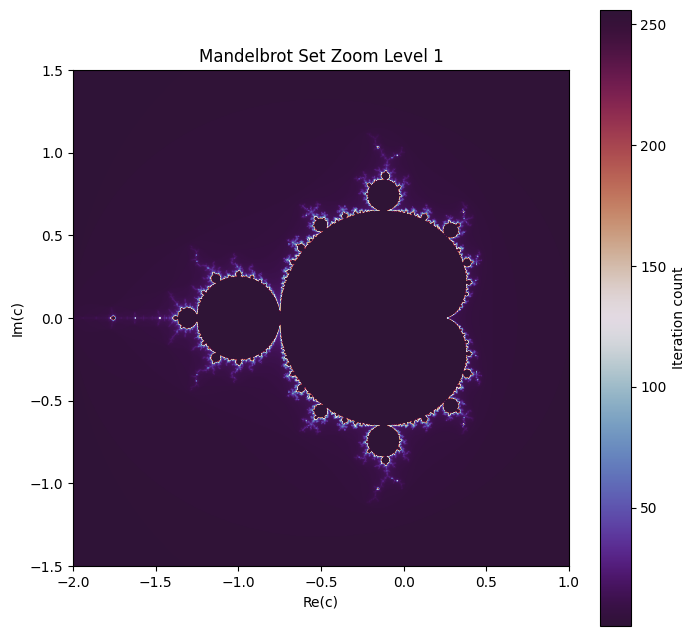

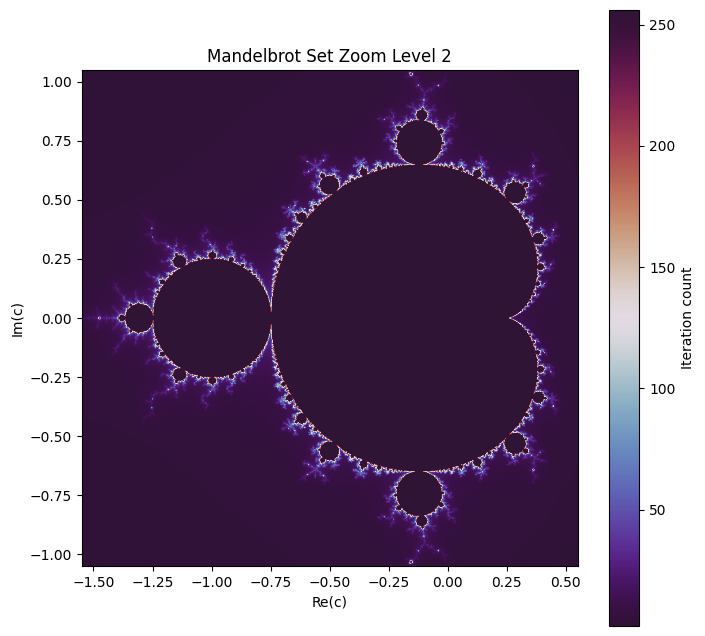

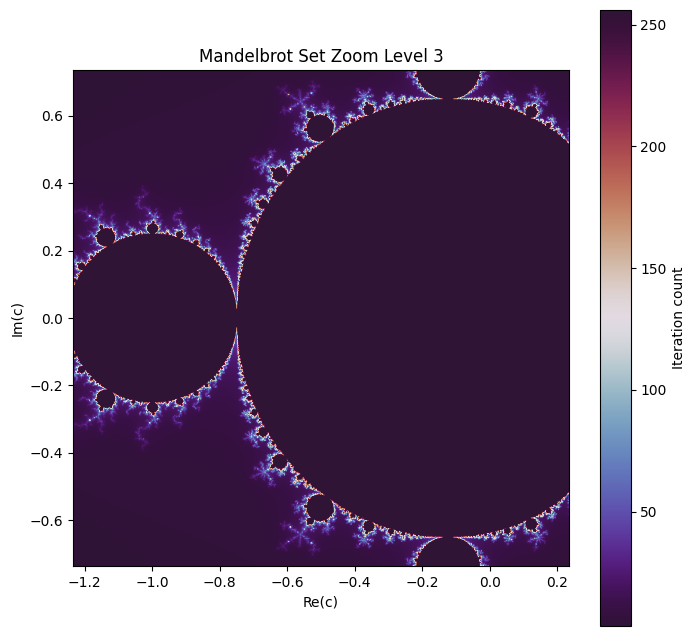

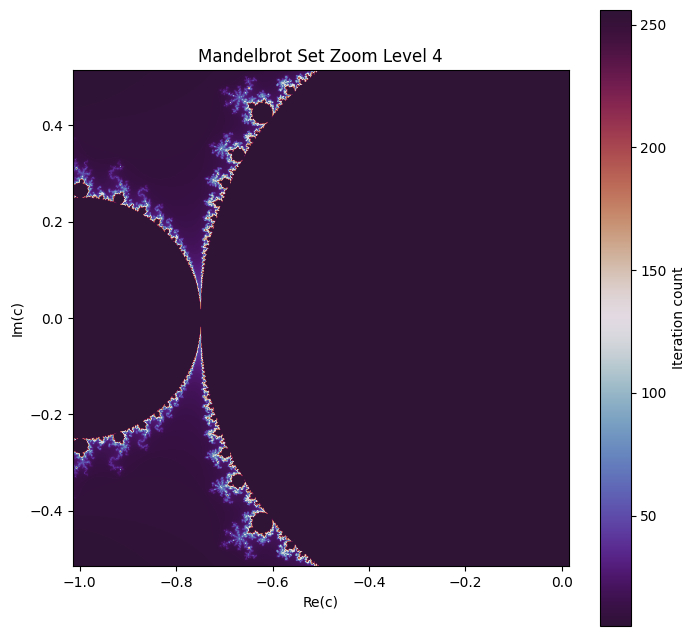

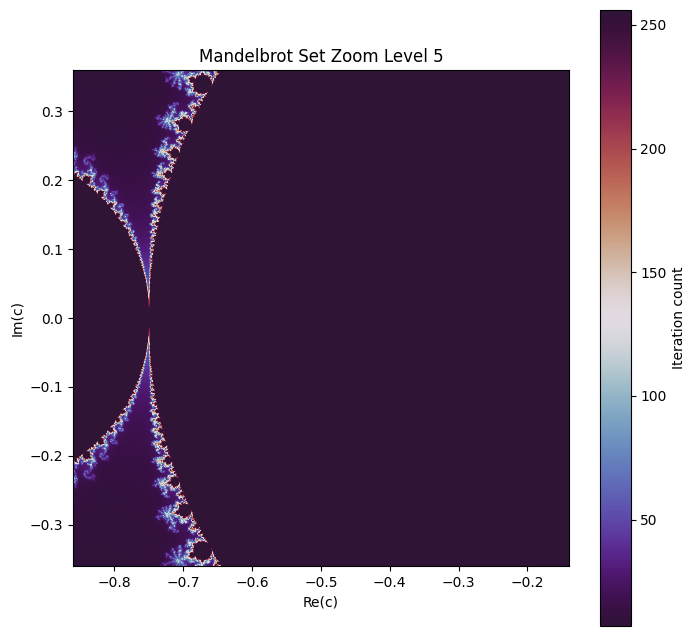

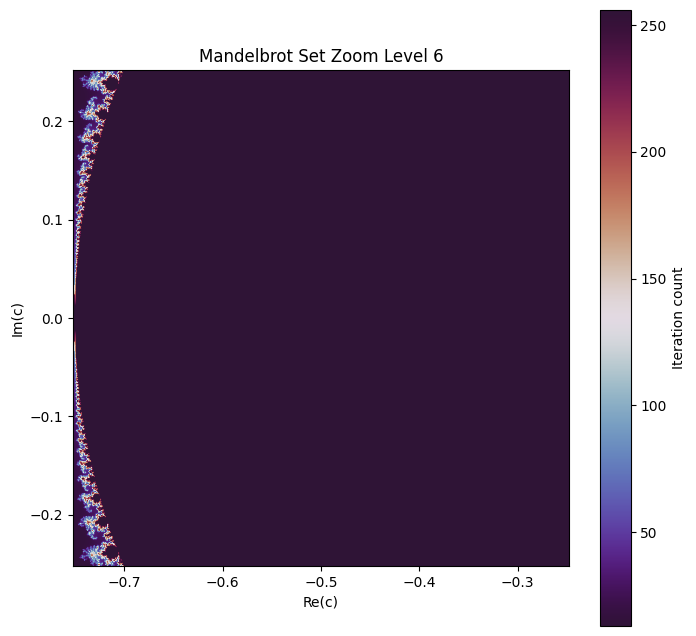

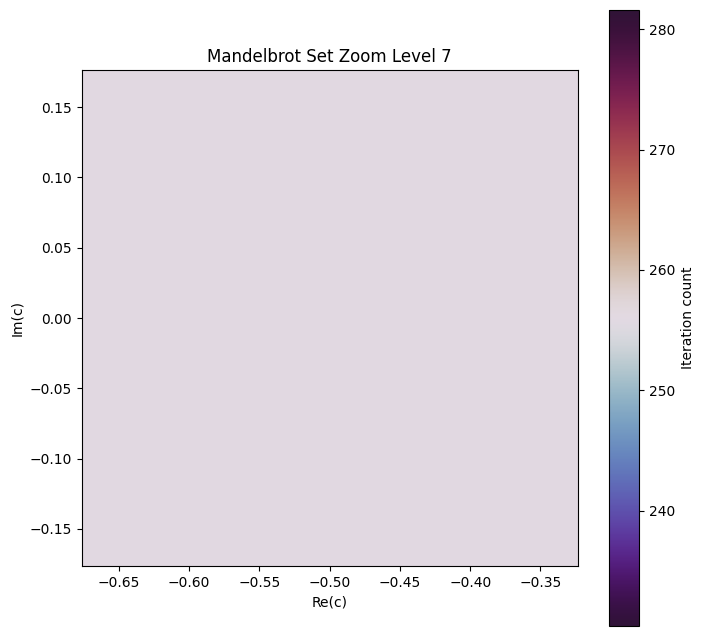

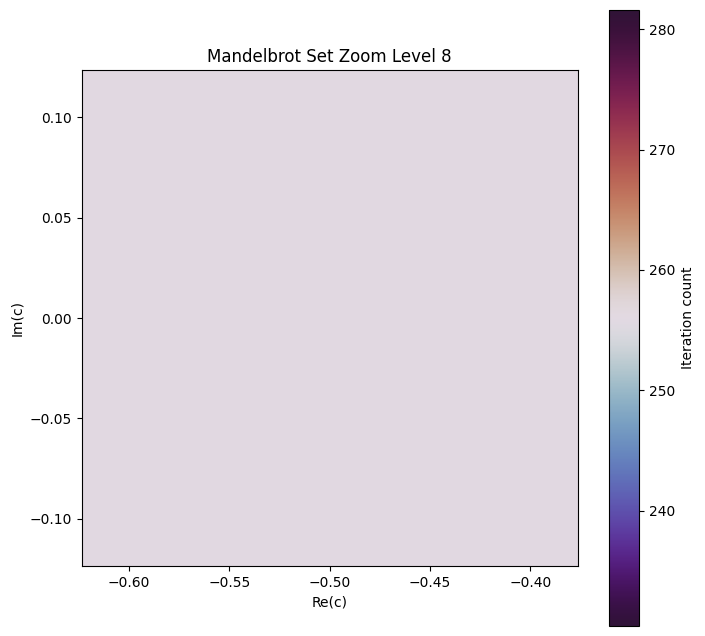

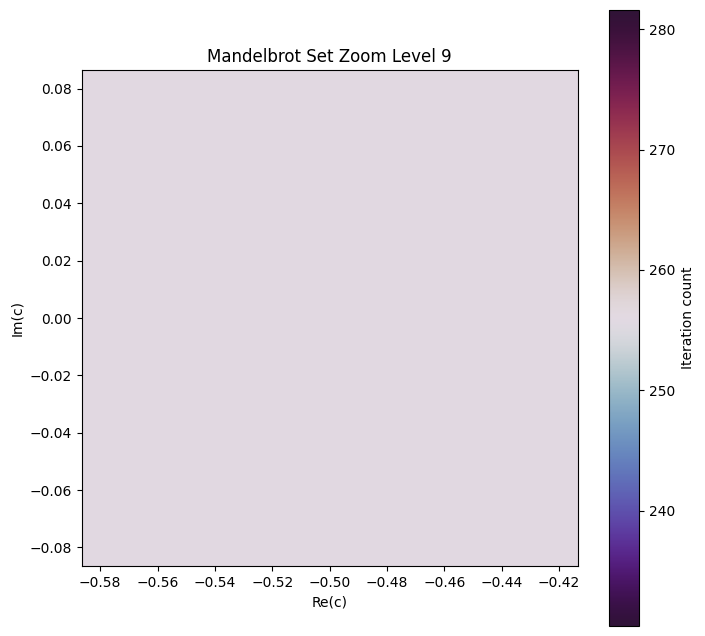

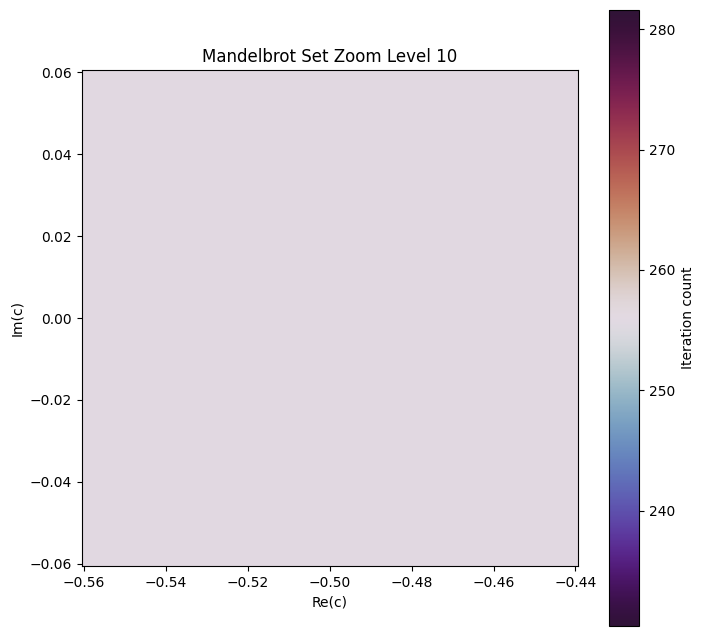

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def mandelbrot(c, max_iter):
    z = 0
    n = 0
    while abs(z) <= 2 and n < max_iter:
        z = z*z + c
        n += 1
    return n

def mandelbrot_set(xmin, xmax, ymin, ymax, width, height, max_iter):
    r1 = np.linspace(xmin, xmax, width)
    r2 = np.linspace(ymin, ymax, height)
    return np.array([[mandelbrot(complex(r, i), max_iter) for r in r1] for i in r2])

# Zoom parameters
center_x, center_y = -0.5, 0   # Center point to zoom into
initial_range = 3.0             # Starting range for both x and y
zoom_factor = 0.7               # Factor by which to reduce range each iteration
zoom_steps = 10                 # Number of zoom levels
width, height = 800, 800        # Image resolution
max_iter = 256                  # Iteration limit for Mandelbrot calculation

# Generate and plot images at each zoom level
for i in range(zoom_steps):
    # Define the current range around the center point
    xmin = center_x - initial_range / 2
    xmax = center_x + initial_range / 2
    ymin = center_y - initial_range / 2
    ymax = center_y + initial_range / 2
    
    # Generate the Mandelbrot set image for the current zoom level
    mandelbrot_image = mandelbrot_set(xmin, xmax, ymin, ymax, width, height, max_iter)
    
    # Plot the Mandelbrot set
    plt.figure(figsize=(8, 8))
    plt.imshow(mandelbrot_image, extent=(xmin, xmax, ymin, ymax), cmap="twilight_shifted", interpolation="bilinear")
    plt.colorbar(label="Iteration count")
    plt.title(f"Mandelbrot Set Zoom Level {i+1}")
    plt.xlabel("Re(c)")
    plt.ylabel("Im(c)")
    plt.show()
    
    # Reduce the range for the next zoom level
    initial_range *= zoom_factor
